In [2]:
import numpy as np
import matplotlib.pyplot as plt
from stl import mesh
from os.path import exists
from base.LBC_centreline import return_LBC_centreline
from base.utils import  return_rings, find_neighbours_with_knn

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [12]:
def plot_centrelines(basename_list, out_fp, lbc_args, ct_args, figsize =(8,6), loc = True):
    arrow_props = dict(zorder=100, scale=0.6, width= 0.01, scale_units= "x", alpha = 0.5)    

    fig = plt.figure(figsize = figsize)

    for c, basename in enumerate(basename_list):

        mesh_filepath = f"./tests/meshes/{basename}.stl"
        meshdata = mesh.Mesh.from_file(mesh_filepath)

        adj_tr_path = f"./tests/meshes/{basename}_adjacent_triangles.txt"

        keep = ct_args["keep"]
        if exists(adj_tr_path) and keep:
            adjacent_triangles = np.loadtxt(adj_tr_path).astype(int)
        else:
            adjacent_triangles = find_neighbours_with_knn(meshdata)
            np.savetxt(adj_tr_path, adjacent_triangles, fmt="%.1d")

            

        centreline_filepath = f"./tests/centrelines/LBC_{basename}_centreline.txt"

        keep_centreline = ct_args["keep_centreline"]
        if exists(centreline_filepath) and keep_centreline:
            centreline = np.loadtxt(centreline_filepath)
            rings = return_rings(meshdata, adjacent_triangles)

        else:
            centreline, rings = return_LBC_centreline(meshdata, 
                                                      adjacent_triangles, 
                                                      ct_down_sample= ct_args["centreline_down_sample"], 
                                                      lbc_args= lbc_args)
            np.savetxt(centreline_filepath, centreline, fmt= "%.3e")
        
        ax = fig.add_subplot(3, len(basename_list), c+1)

        ax.scatter(*meshdata.centroids[::100, [0,1]].T, color = "lightgrey", alpha = 0.5, s = 2, zorder = -100)
        ax.scatter(*rings["ring1"][:, [0,1]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*rings["ring2"][:, [0,1]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*rings["P1"][[0,1]] ,*rings["nP1"][[0,1]],color = "C0", **arrow_props)
        ax.quiver(*rings["P2"][[0,1]] ,*rings["nP2"][[0,1]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,1]].T, "-o", markersize=1, color = "k", zorder= -90)

        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        if loc != False:
            ax.set_xlim(-8,8)
            ax.set_ylim(-8,8)
        ax.set_aspect("equal")

        ax = fig.add_subplot(3, len(basename_list), len(basename_list)+c+1)

        ax.scatter(*meshdata.centroids[::100, [0,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*rings["ring1"][:, [0,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*rings["ring2"][:, [0,2]].T, c="C1", s = 2, label = "ring 2")
        ax.quiver(*rings["P1"][[0,2]] ,*rings["nP1"][[0,2]],color = "C0", **arrow_props)
        ax.quiver(*rings["P2"][[0,2]] ,*rings["nP2"][[0,2]],color = "C1", **arrow_props)
        ax.plot(*centreline[:, [0,2]].T, "-o", markersize=1, color = "k")

        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        if loc != False:
            ax.set_xlim(-8,8)
            ax.set_ylim(-8,8)
        ax.set_aspect("equal")


        ax = fig.add_subplot(3, len(basename_list), 2*len(basename_list)+c+1)

        ax.scatter(*meshdata.centroids[::100, [1,2]].T, color = "lightgrey", alpha = 0.5, s = 2)
        ax.scatter(*rings["ring1"][:, [1,2]].T, c="C0", s = 2, label = "ring 1")
        ax.scatter(*rings["ring2"][:, [1,2]].T, c="C1", s = 2, label = "ring 2")
        ax.plot(*centreline[:, [1,2]].T, "-o", markersize=1, color = "k")

        ax.set_xlabel('Y')
        ax.set_ylabel('Z')
        if loc != False:
            ax.set_xlim(-8,8)
            ax.set_ylim(-8,8)
        ax.set_aspect("equal")


        #ax.legend()
    plt.tight_layout()
    plt.savefig(out_fp, dpi = 300)
    plt.show()

In [15]:
basenames_simple = ["straight_cylinder_L10_R1",
             "straight_elliptical_prism_L10_R1_R05",
             "straight_cylinder_L10_R_variable"]
out_fp = "./tests/outputs/finding_inlet_outlet_rings_and_centrelines_LBC_simple.png"

lbc_args = dict(init_attraction = 0.5, init_contraction = 0.5, down_sample = 0.2)
ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = 0.2)

read file in 0.0000s


2025-03-06 12:01:04,185 - PCD #points: 2000


contracted file in 1.1231s


Current volume ratio 1.0. Contraction weights 354.0875757639706. Attraction weights 9.149219950668824. Progress LBC:  12025-03-06 12:01:05,219 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 354.0875757639706. Attraction weights 9.149219950668824. Progress LBC:  1


Contraction is Done.
extracted skeleton in 1.0607s
downsampled the centreline cloud in 0.0020s
there were 0 connected components.
found largest component in 0.0000s
computed minimum spanning tree in 0.0061s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0000s
found ring 1 with 715 points.
found ring 2 with 715 points.
computed shortest path in  0.1532s
read file in 0.0000s


...

read file in 0.0000s


2025-03-06 12:01:10,285 - PCD #points: 2289


contracted file in 1.2630s


Current volume ratio 1.0. Contraction weights 328.98781624386436. Attraction weights 3.688093242156026. Progress LBC:  2025-03-06 12:01:11,915 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 328.98781624386436. Attraction weights 3.688093242156026. Progress LBC:  

Contraction is Done.
extracted skeleton in 1.6523s
downsampled the centreline cloud in 0.0020s
there were 0 connected components.
found largest component in 0.0000s
computed minimum spanning tree in 0.0040s
created graph instance of the centreline in  0.0000s
added node coordinates to graph in  0.0010s
found ring 1 with 783 points.
found ring 2 with 765 points.
computed shortest path in  0.1234s


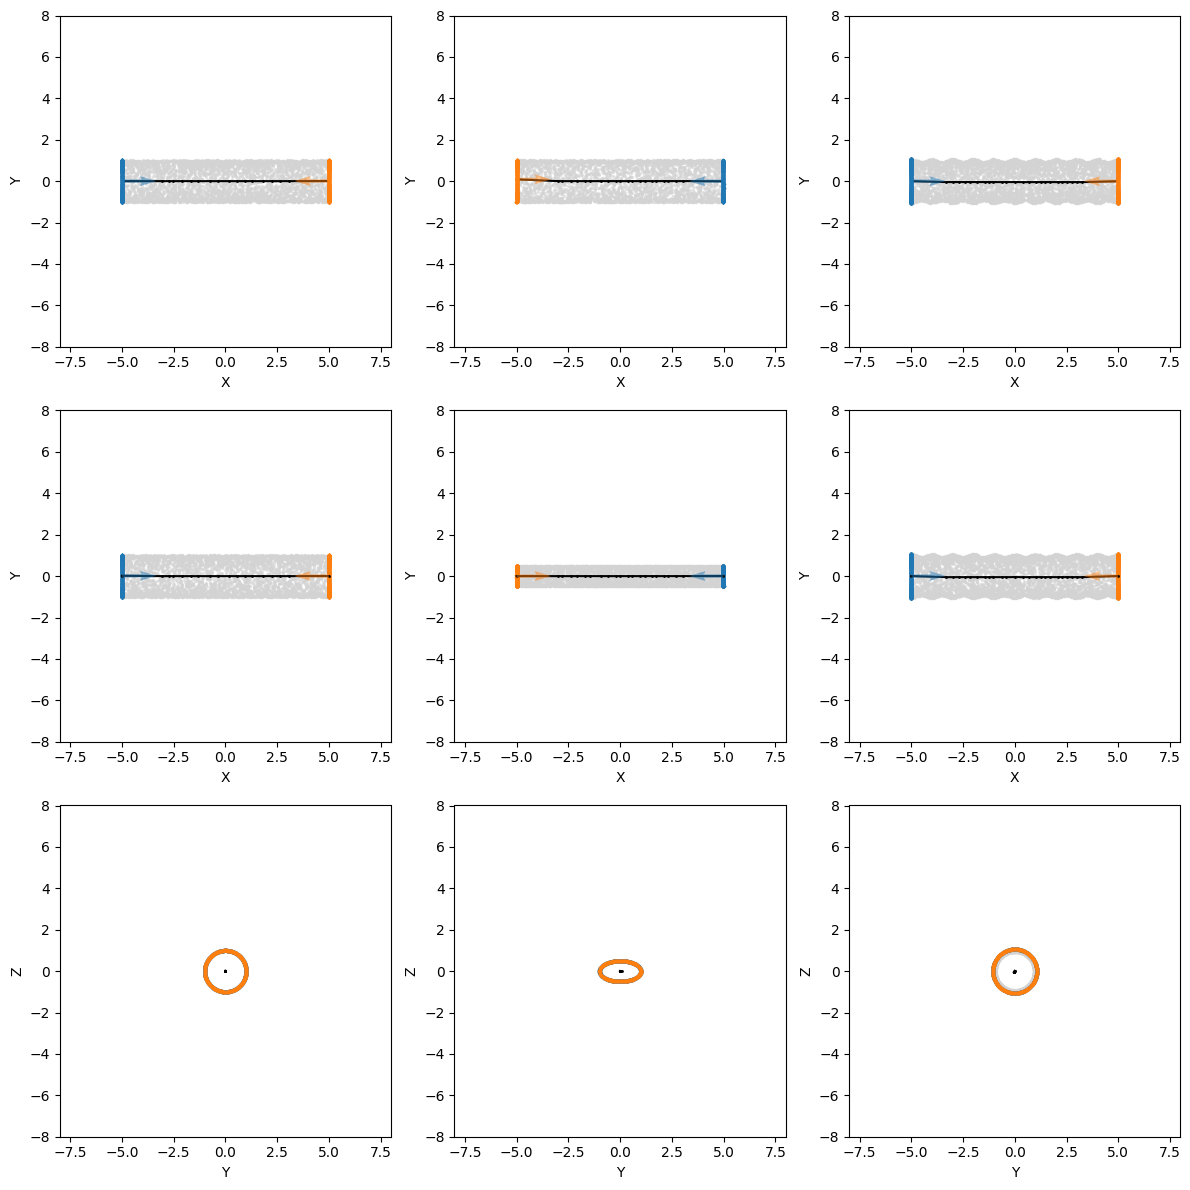

In [16]:
plot_centrelines(basenames_simple, out_fp, lbc_args, ct_args, figsize=(12,12))

In [38]:
basenames_complex = ["straight_cylinder_L8_R1_stochastic","sinuous_D5_r_1","extra_sinuous_D5_r_1"]

In [39]:
plot_centrelines(basenames_complex, "./tests/outputs/finding_inlet_outlet_rings_and_centrelines_LBC_complex.png", figsize=(12,12))

found ring 1 with 835 points.
found ring 2 with 833 points.
read file in 0.0000s


2025-03-06 07:16:41,317 - PCD #points: 1160


contracted file in 0.9321s


Current volume ratio 1.0. Contraction weights 209.75580945668204. Attraction weights 0.19999999999999998. Progress LBC:2025-03-06 07:16:41,620 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 209.75580945668204. Attraction weights 0.19999999999999998. Progress LBC:


Contraction is Done.
extracted skeleton in 0.3179s
downsampled the centreline cloud in 0.0000s
there were 0 connected components.
found largest component in 0.0000s


ValueError: Expected n_neighbors < n_samples_fit, but n_neighbors = 5, n_samples_fit = 1, n_samples = 1

<Figure size 1200x1200 with 0 Axes>

In [7]:
basenames_cave = ["Riesengang_subset", "Motiers", "Faux-Monnayeurs", "Archamps", "Lauiloch"]

found ring 1 with 322 points.
found ring 2 with 241 points.
read file in 0.0000s


2025-03-06 07:51:05,984 - PCD #points: 64128


contracted file in 4.1356s


Current volume ratio 1.0. Contraction weights 2048.0. Attraction weights 1.411260035894092. Progress LBC:  15%|▏| 3/20 2025-03-06 07:52:35,212 - Contraction is Done.


Contraction is Done.


...

contracted file in 2.2659s


Current volume ratio 1.0. Contraction weights 2048.0. Attraction weights 5.237745694270716. Progress LBC:  15%|▏| 3/20 2025-03-06 07:54:41,254 - Contraction is Done.


Contraction is Done.


Current volume ratio 1.0. Contraction weights 2048.0. Attraction weights 5.237745694270716. Progress LBC:  15%|▏| 3/20 


extracted skeleton in 13.1819s
downsampled the centreline cloud in 0.0000s
there were 0 connected components.
found largest component in 0.1478s
computed minimum spanning tree in 0.0000s
created graph instance of the centreline in  0.0160s
added node coordinates to graph in  0.0000s
found ring 1 with 190 points.
found ring 2 with 188 points.
computed shortest path in  0.1502s


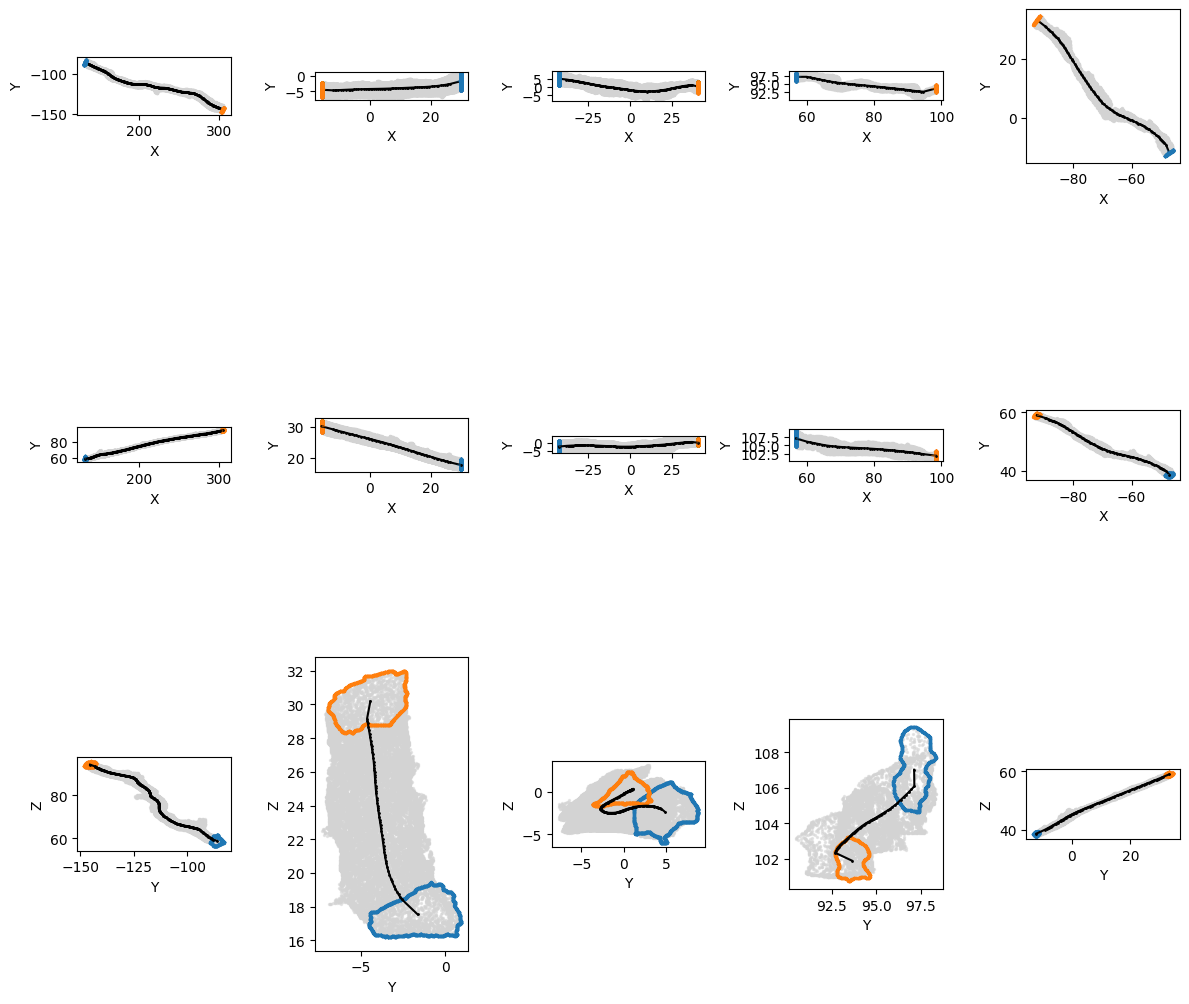

In [8]:
plot_centrelines(basenames_cave, "./tests/outputs/finding_inlet_outlet_rings_and_centrelines_LBC_cave.png", figsize=(12,12), loc= False)